In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text

## Volcano plot


In [2]:
RESULTS = "IBPGG\\IBP project\\results"

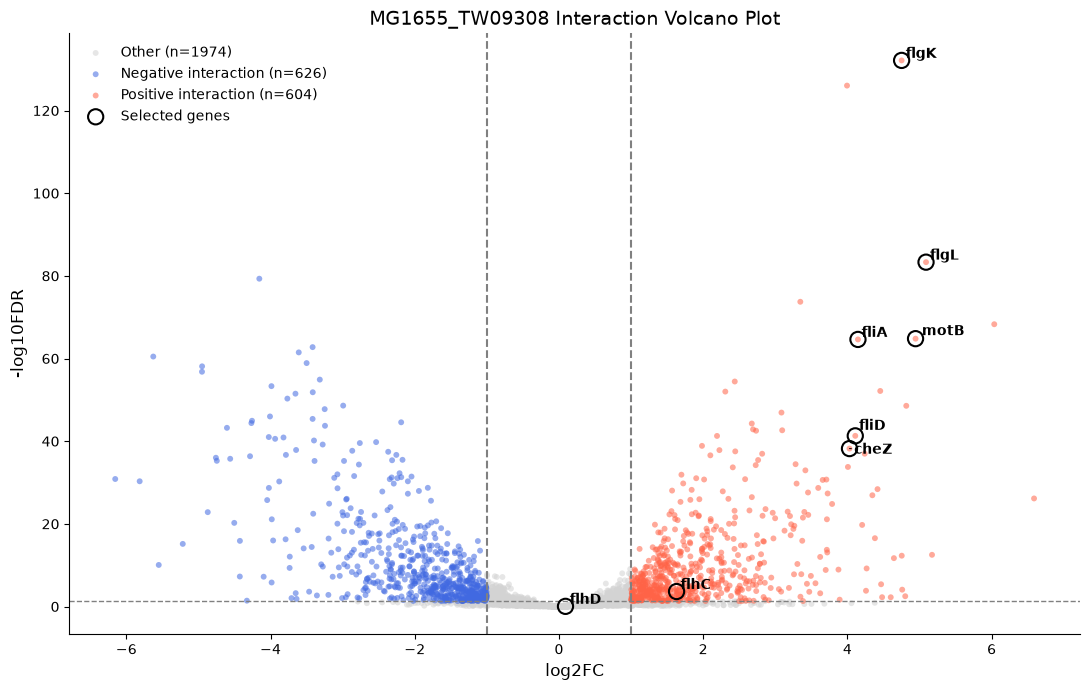

In [3]:
# Configuration
DE_MG1655_TW09308 = pd.read_csv(f"{RESULTS}\\DE_MG1655_TW09308.csv")
pairdata = DE_MG1655_TW09308.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["interaction_log2FoldChange", "interaction_padj"]).copy()

min_p = df.loc[df["interaction_padj"] > 0, "interaction_padj"].min()

df["neg_log10_padj"] = -np.log10(df["interaction_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["interaction_padj"] < fdr_cutoff) &
    (df["interaction_log2FoldChange"] > lfc_cutoff))
down = (
    (df["interaction_padj"] < fdr_cutoff) &
    (df["interaction_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "interaction_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["interaction_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["interaction_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["interaction_ci_low"]
        high = row["interaction_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "MG1655_TW09308 Interaction Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

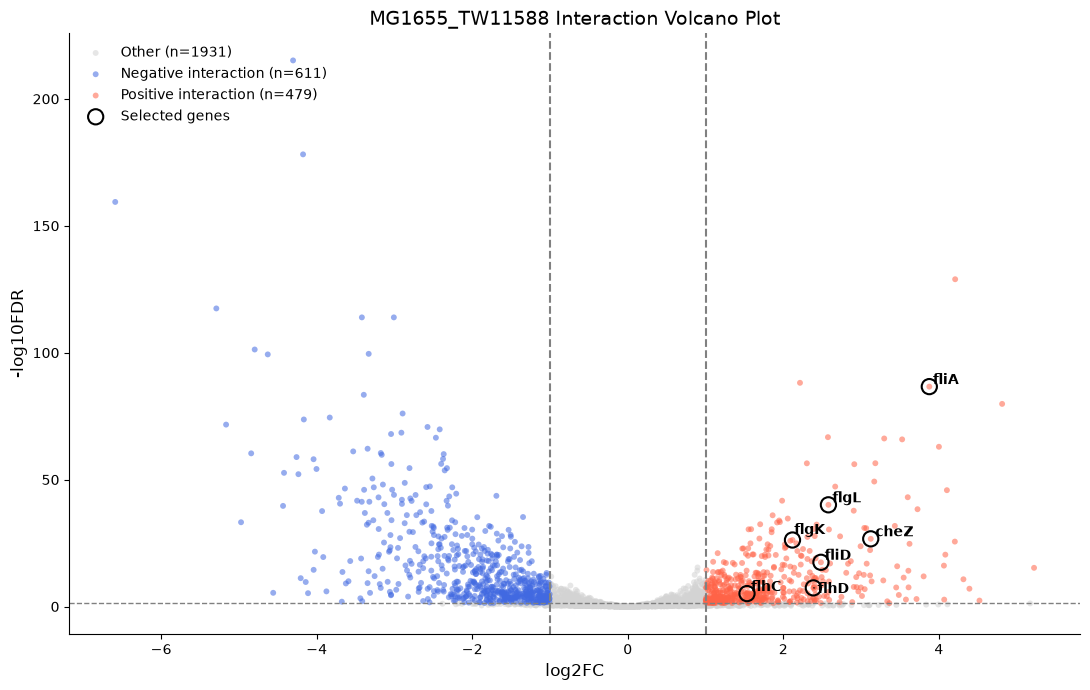

In [4]:
# Configuration
DE_MG1655_TW11588 = pd.read_csv(f"{RESULTS}\\DE_MG1655_TW11588.csv")
pairdata = DE_MG1655_TW11588.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["interaction_log2FoldChange", "interaction_padj"]).copy()

min_p = df.loc[df["interaction_padj"] > 0, "interaction_padj"].min()

df["neg_log10_padj"] = -np.log10(df["interaction_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["interaction_padj"] < fdr_cutoff) &
    (df["interaction_log2FoldChange"] > lfc_cutoff))
down = (
    (df["interaction_padj"] < fdr_cutoff) &
    (df["interaction_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "interaction_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["interaction_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["interaction_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["interaction_ci_low"]
        high = row["interaction_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "MG1655_TW11588 Interaction Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

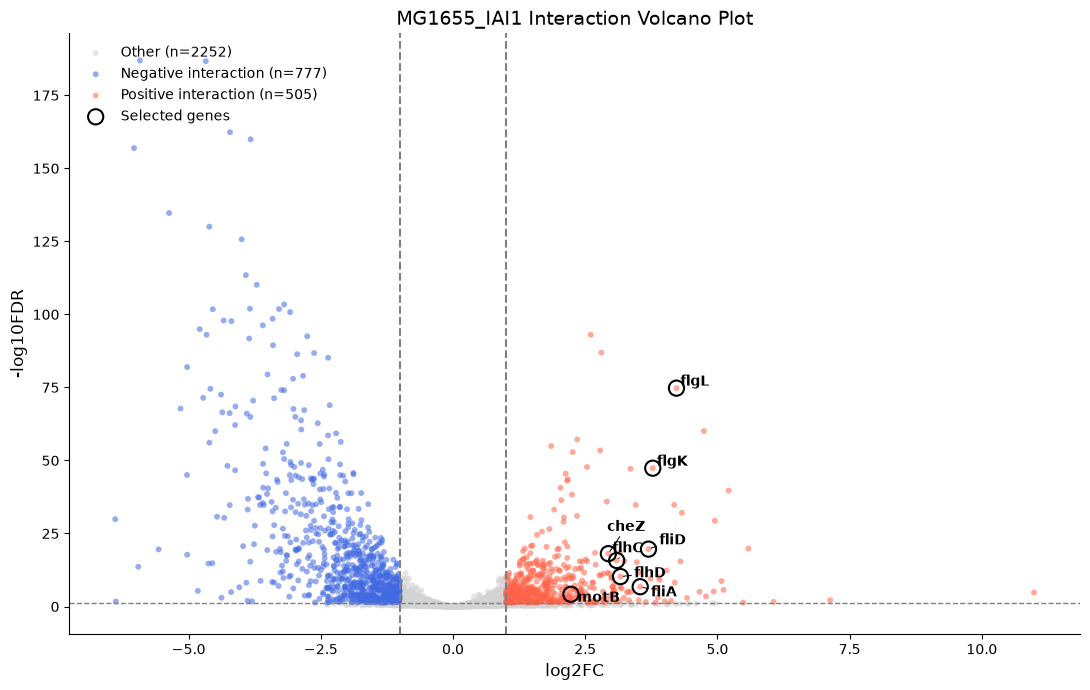

In [5]:
# Configuration
DE_MG1655_IAI1 = pd.read_csv(f"{RESULTS}\\DE_MG1655_IAI1.csv")
pairdata = DE_MG1655_IAI1.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["interaction_log2FoldChange", "interaction_padj"]).copy()

min_p = df.loc[df["interaction_padj"] > 0, "interaction_padj"].min()

df["neg_log10_padj"] = -np.log10(df["interaction_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["interaction_padj"] < fdr_cutoff) &
    (df["interaction_log2FoldChange"] > lfc_cutoff))
down = (
    (df["interaction_padj"] < fdr_cutoff) &
    (df["interaction_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "interaction_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["interaction_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["interaction_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["interaction_ci_low"]
        high = row["interaction_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "MG1655_IAI1 Interaction Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

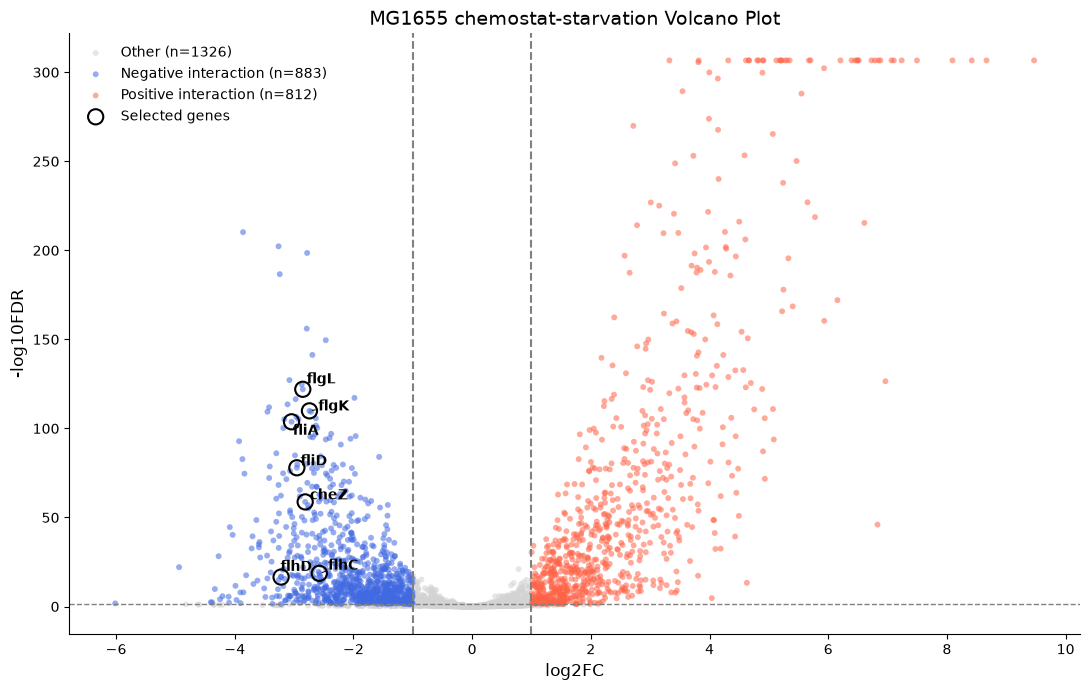

In [6]:
# Configuration
DE_MG1655_TW11588 = pd.read_csv(f"{RESULTS}\\DE_MG1655_TW11588.csv")
pairdata = DE_MG1655_TW11588.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["MG1655_log2FoldChange", "MG1655_padj"]).copy()

min_p = df.loc[df["MG1655_padj"] > 0, "MG1655_padj"].min()

df["neg_log10_padj"] = -np.log10(df["MG1655_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["MG1655_padj"] < fdr_cutoff) &
    (df["MG1655_log2FoldChange"] > lfc_cutoff))
down = (
    (df["MG1655_padj"] < fdr_cutoff) &
    (df["MG1655_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "MG1655_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["MG1655_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["MG1655_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["MG1655_ci_low"]
        high = row["MG1655_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "MG1655 chemostat-starvation Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

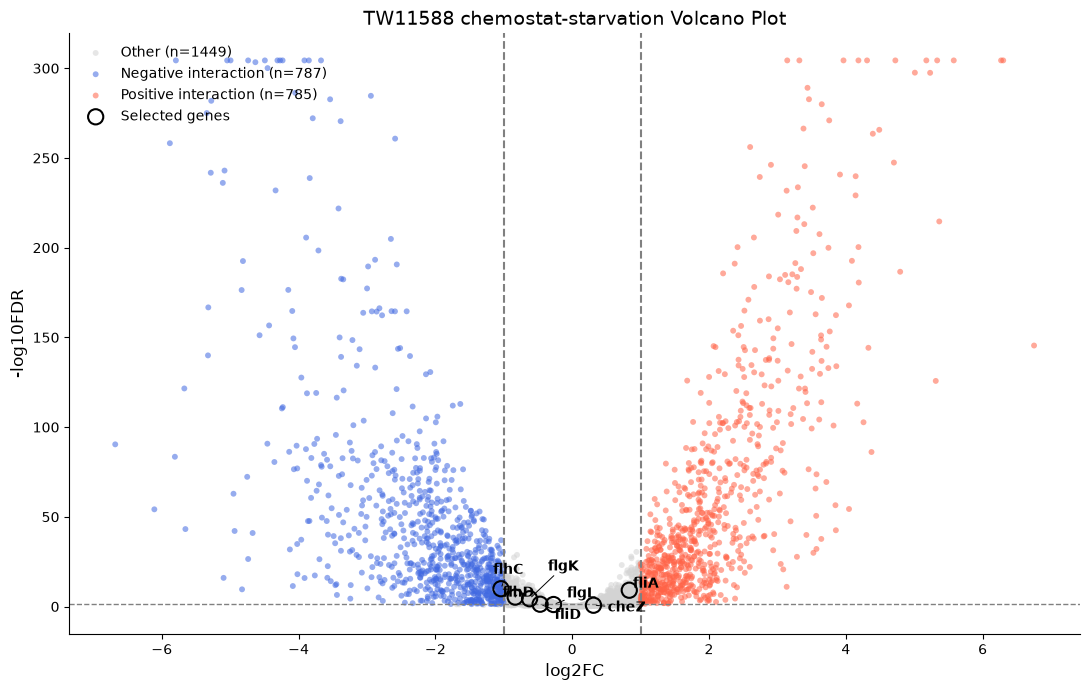

In [7]:
# Configuration
DE_MG1655_TW11588 = pd.read_csv(f"{RESULTS}\\DE_MG1655_TW11588.csv")
pairdata = DE_MG1655_TW11588.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["relative_log2FoldChange", "relative_padj"]).copy()

min_p = df.loc[df["relative_padj"] > 0, "relative_padj"].min()

df["neg_log10_padj"] = -np.log10(df["relative_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["relative_padj"] < fdr_cutoff) &
    (df["relative_log2FoldChange"] > lfc_cutoff))
down = (
    (df["relative_padj"] < fdr_cutoff) &
    (df["relative_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "relative_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["relative_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["relative_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["relative_ci_low"]
        high = row["relative_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "TW11588 chemostat-starvation Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

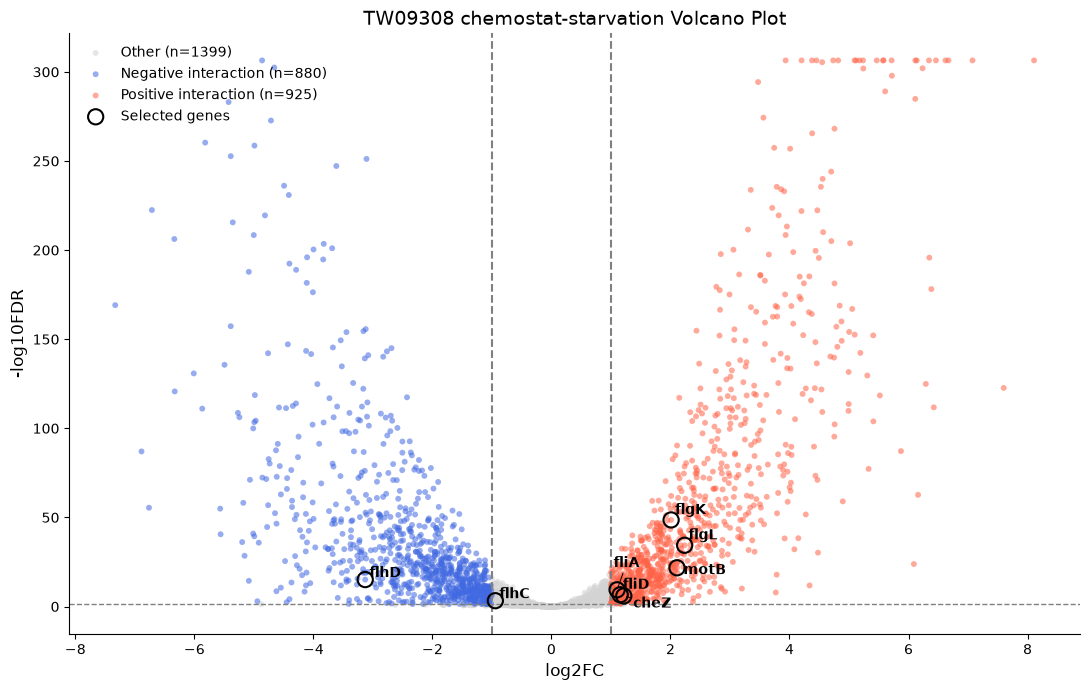

In [8]:
# Configuration
pairdata = DE_MG1655_TW09308.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["relative_log2FoldChange", "relative_padj"]).copy()

min_p = df.loc[df["relative_padj"] > 0, "relative_padj"].min()

df["neg_log10_padj"] = -np.log10(df["relative_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["relative_padj"] < fdr_cutoff) &
    (df["relative_log2FoldChange"] > lfc_cutoff))
down = (
    (df["relative_padj"] < fdr_cutoff) &
    (df["relative_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "relative_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["relative_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["relative_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["relative_ci_low"]
        high = row["relative_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "TW09308 chemostat-starvation Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

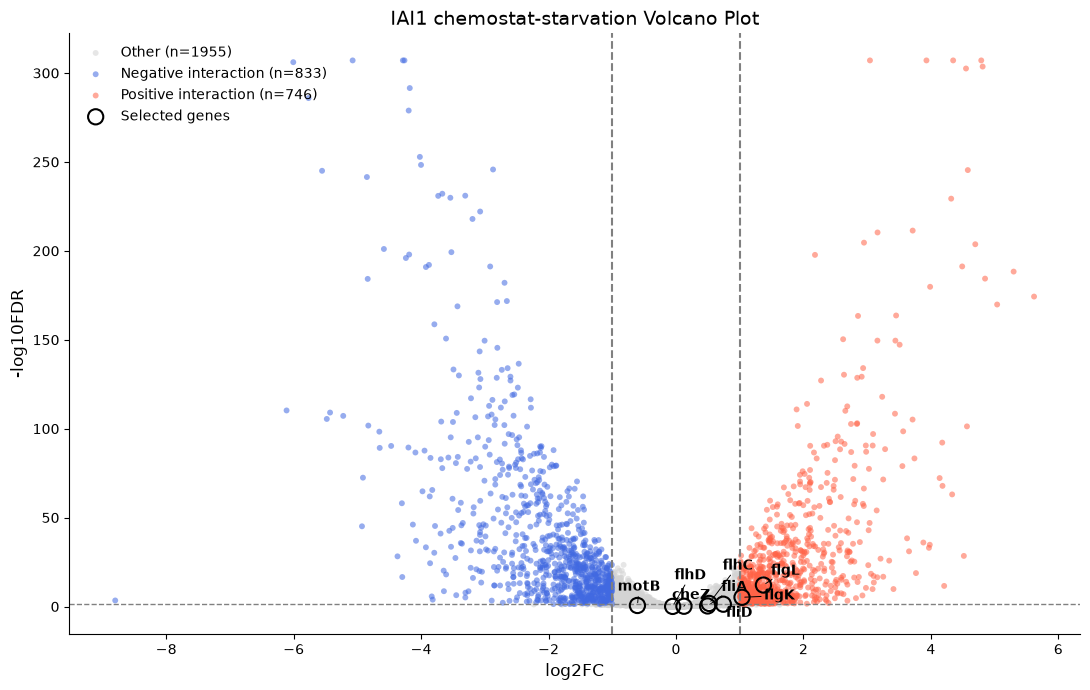

In [9]:
# Configuration
pairdata = DE_MG1655_IAI1.copy()
genes_to_label = ["flgK", "flgL", "cheZ", "motB", "flhC", "flhD", "fliA", "fliD"]

fdr_cutoff = 0.05
lfc_cutoff = 1
show_ci = False  # Change to True to show 95% CI

# Prepare data
df = pairdata.dropna(subset=["relative_log2FoldChange", "relative_padj"]).copy()

min_p = df.loc[df["relative_padj"] > 0, "relative_padj"].min()

df["neg_log10_padj"] = -np.log10(df["relative_padj"].clip(lower=min_p / 10))

# Classify interactions
up = (
    (df["relative_padj"] < fdr_cutoff) &
    (df["relative_log2FoldChange"] > lfc_cutoff))
down = (
    (df["relative_padj"] < fdr_cutoff) &
    (df["relative_log2FoldChange"] < -lfc_cutoff))
other = ~(up | down)

fig, ax = plt.subplots(figsize=(11, 7))
for mask, color, name in [
    (other, "lightgray", "Other"),
    (down, "royalblue", "Negative interaction"),
    (up, "tomato", "Positive interaction")]:
    ax.scatter(
        df.loc[mask, "relative_log2FoldChange"],
        df.loc[mask, "neg_log10_padj"],
        c=color,
        s=18,
        alpha=0.55,
        edgecolors="none",
        label=f"{name} (n={mask.sum()})")

# Highlight selected genes with black open circles
selected = df[df["gene_name"].isin(genes_to_label)]

ax.scatter(
    selected["relative_log2FoldChange"],
    selected["neg_log10_padj"],
    s=120,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
    label="Selected genes"
)

# Add text labels
texts = []

for _, row in selected.iterrows():

    x = row["relative_log2FoldChange"]
    y = row["neg_log10_padj"]

    texts.append(
        ax.text(
            x, y,
            row["gene_name"],
            fontsize=10,
            fontweight="bold",
            zorder=6
        )
    )

    # Optional 95% confidence interval
    if show_ci:
        low = row["relative_ci_low"]
        high = row["relative_ci_high"]

        if np.isfinite(low) and np.isfinite(high):
            ax.errorbar(
                x, y,
                xerr=[[max(0, x - low)],
                      [max(0, high - x)]],
                fmt="none",
                ecolor="black",
                capsize=3,
                linewidth=1,
                zorder=4
            )

# Significance thresholds
ax.axhline(
    -np.log10(fdr_cutoff),
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(-lfc_cutoff, color="gray", linestyle="--")
ax.axvline(lfc_cutoff, color="gray", linestyle="--")

# Axes
ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("-log10FDR", fontsize=12)
ax.set_title(
    "IAI1 chemostat-starvation Volcano Plot",
    fontsize=14
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

# Automatically adjust labels
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.7
    )
)

plt.tight_layout()
plt.show()

## Imodulon

class I belongs to Crp ( Crp activates transcription of genes for alternative carbon source utilization when glucose is limiting), and FlhDC-2

class II highly overlops with FlhDC-2

class II ... with FliA

In [10]:
class1 = ["flhD", "flhC"]
class2 = [
    # flgAMN
    "flgA", "flgM", "flgN",
    # flgBCDEFGHIJ
    "flgB", "flgC", "flgD", "flgE", "flgF",
    "flgG", "flgH", "flgI", "flgJ",
    # flhBAE
    "flhB", "flhA", "flhE",
    # fliAZY
    "fliA", "fliZ", "fliY",
    # fliE
    "fliE",
    # fliFGHIJK
    "fliF", "fliG", "fliH", "fliI", "fliJ", "fliK",
    # fliLMNOPQR
    "fliL", "fliM", "fliN", "fliO",
    "fliP", "fliQ", "fliR"]

class3 = [
    # flgKL
    "flgK", "flgL",
    # fliDST
    "fliD", "fliS", "fliT",
    # flgMN
    "flgM", "flgN",
    # fliC
    "fliC",
    # tar-tap-cheRBYZ
    "tar", "tap", "cheR", "cheB", "cheY", "cheZ",
    # motAB-cheAW
    "motA", "motB", "cheA", "cheW"
]

In [11]:
import pandas as pd
iModulons = pd.read_csv("iModulons.csv", header=0)
modulon_dict = {
    modulon: set(iModulons.loc[iModulons[modulon] == 1, iModulons.columns[0]])
    for modulon in iModulons.columns[1:]
}  # iModulon: (genes)

gene_modulon_dict = {
    row[iModulons.columns[0]]: {
        modulon
        for modulon in iModulons.columns[1:]
        if row[modulon] == 1
    }
    for _, row in iModulons.iterrows()
    if row[iModulons.columns[1:]].sum() > 0
}# gene: (iMoludons it involves)

In [12]:
FliA_im = modulon_dict["FliA"]
FlhDC_1_im = modulon_dict["FlhDC-1"]
FlhDC_2_im = modulon_dict["FlhDC-2"]

In [13]:
audit = pd.read_csv("IBPGG\\IBP project\\results\\ortholog_audit_all.csv",index_col=0)

audit = audit[["gene_id", "gene_name"]]


In [14]:
gene_map = audit.dropna(subset=["gene_id"]).set_index("gene_id")["gene_name"].to_dict()

FliA_genes = [gene_map.get(gid, gid) for gid in FliA_im]
FlhDC_1_genes = [gene_map.get(gid, gid) for gid in FlhDC_1_im]
FlhDC_2_genes = [gene_map.get(gid, gid) for gid in FlhDC_2_im]

In [15]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

def plot_venn2(list1, list2, label1="List 1", label2="List 2"):
    set1, set2 = set(list1), set(list2)

    fig, ax = plt.subplots(figsize=(6, 6))
    venn2([set1, set2], set_labels=(label1, label2), ax=ax)

    plt.tight_layout()
    plt.show()

    print(f"\n{label1} only ({len(set1 - set2)}):")
    print(sorted(set1 - set2))

    print(f"\n{label2} only ({len(set2 - set1)}):")
    print(sorted(set2 - set1))

    print(f"\nOverlap ({len(set1 & set2)}):")
    print(sorted(set1 & set2))

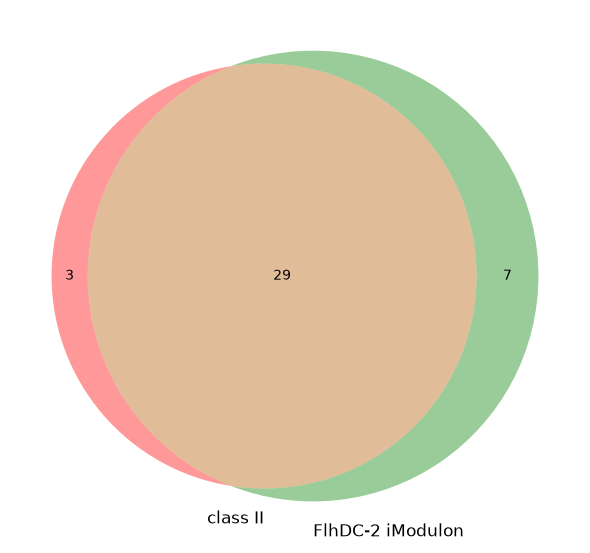


class II only (3):
['flgM', 'flgN', 'fliY']

FlhDC-2 iModulon only (7):
['csgC', 'flgK', 'flhC', 'fliD', 'fliS', 'yecR', 'ymdA']

Overlap (29):
['flgA', 'flgB', 'flgC', 'flgD', 'flgE', 'flgF', 'flgG', 'flgH', 'flgI', 'flgJ', 'flhA', 'flhB', 'flhE', 'fliA', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'fliK', 'fliL', 'fliM', 'fliN', 'fliO', 'fliP', 'fliQ', 'fliR', 'fliZ']


In [16]:
plot_venn2(class2, FlhDC_2_genes, "class II", "FlhDC-2 iModulon")

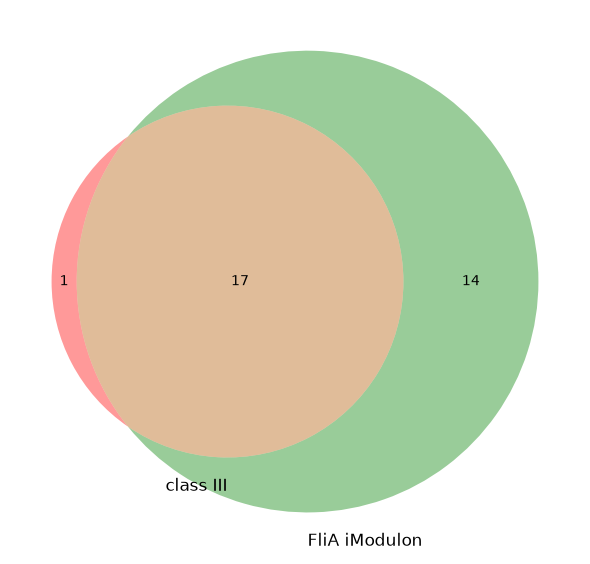


class III only (1):
['fliC']

FliA iModulon only (14):
['aer', 'b1923', 'fliZ', 'flxA', 'modA', 'trg', 'tsr', 'uhpT', 'ves', 'ycgR', 'yhjH', 'yjcZ', 'yjdA', 'ynjH']

Overlap (17):
['cheA', 'cheB', 'cheR', 'cheW', 'cheY', 'cheZ', 'flgK', 'flgL', 'flgM', 'flgN', 'fliD', 'fliS', 'fliT', 'motA', 'motB', 'tap', 'tar']


In [17]:
plot_venn2(class3, FliA_genes, "class III", "FliA iModulon")

In [18]:
print(f"flhD:{gene_modulon_dict["b1892"]}")
print(f"flhC:{gene_modulon_dict["b1891"]}")

flhD:{'Crp'}
flhC:{'Crp', 'FlhDC-2'}


In [19]:
import matplotlib.pyplot as plt
from venn import venn
from itertools import combinations

def plot_venn(*lists, labels=None):
    if labels is None:
        labels = [f"List {i+1}" for i in range(len(lists))]

    if not 2 <= len(lists) <= 6:
        raise ValueError("Supports 2–6 lists")
    if len(labels) != len(lists) or len(set(labels)) != len(labels):
        raise ValueError("Provide one unique label per list")

    data = {
        label: set(genes)
        for label, genes in zip(labels, lists)
    }

    fig, ax = plt.subplots(figsize=(9, 7))
    venn(data, ax=ax)
    plt.show()

    # Print genes in every exclusive region
    for n in range(1, len(labels) + 1):
        for group in combinations(labels, n):
            shared = set.intersection(*(data[g] for g in group))

            others = set().union(
                *(data[g] for g in labels if g not in group)
            )

            genes = sorted(shared - others)

            print(f"\n{' & '.join(group)} only ({len(genes)}):")
            print(genes)

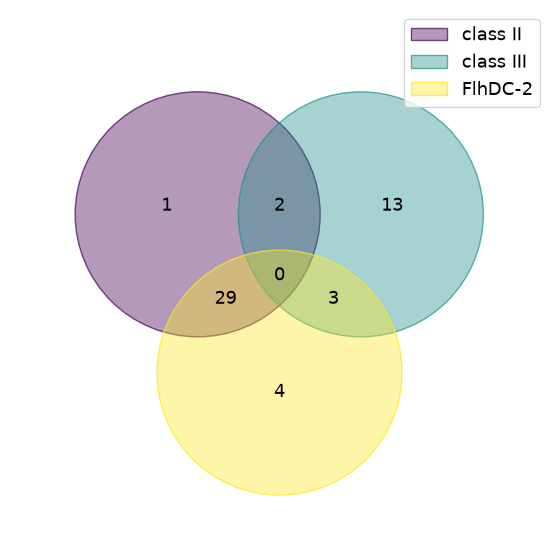


class II only (1):
['fliY']

class III only (13):
['cheA', 'cheB', 'cheR', 'cheW', 'cheY', 'cheZ', 'flgL', 'fliC', 'fliT', 'motA', 'motB', 'tap', 'tar']

FlhDC-2 only (4):
['csgC', 'flhC', 'yecR', 'ymdA']

class II & class III only (2):
['flgM', 'flgN']

class II & FlhDC-2 only (29):
['flgA', 'flgB', 'flgC', 'flgD', 'flgE', 'flgF', 'flgG', 'flgH', 'flgI', 'flgJ', 'flhA', 'flhB', 'flhE', 'fliA', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'fliK', 'fliL', 'fliM', 'fliN', 'fliO', 'fliP', 'fliQ', 'fliR', 'fliZ']

class III & FlhDC-2 only (3):
['flgK', 'fliD', 'fliS']

class II & class III & FlhDC-2 only (0):
[]


In [20]:
plot_venn(
    class2,
    class3,
    FlhDC_2_genes,
    labels=["class II", "class III", "FlhDC-2"]
)

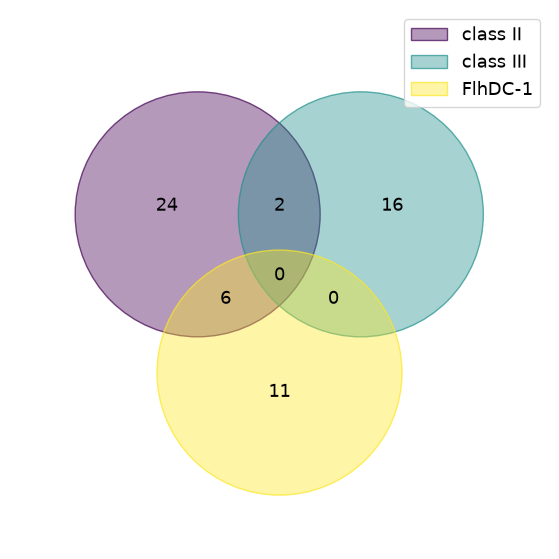


class II only (24):
['flgA', 'flgE', 'flgF', 'flgG', 'flgH', 'flgI', 'flgJ', 'flhA', 'flhB', 'flhE', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'fliK', 'fliL', 'fliM', 'fliN', 'fliO', 'fliP', 'fliY', 'fliZ']

class III only (16):
['cheA', 'cheB', 'cheR', 'cheW', 'cheY', 'cheZ', 'flgK', 'flgL', 'fliC', 'fliD', 'fliS', 'fliT', 'motA', 'motB', 'tap', 'tar']

FlhDC-1 only (11):
['aer', 'b4794', 'csgC', 'rcnA', 'rcnR', 'rcsA', 'trg', 'yecR', 'yhjG', 'ymdA', 'ymdB']

class II & class III only (2):
['flgM', 'flgN']

class II & FlhDC-1 only (6):
['flgB', 'flgC', 'flgD', 'fliA', 'fliQ', 'fliR']

class III & FlhDC-1 only (0):
[]

class II & class III & FlhDC-1 only (0):
[]


In [21]:
plot_venn(
    class2,
    class3,
    FlhDC_1_genes,
    labels=["class II", "class III", "FlhDC-1"]
)

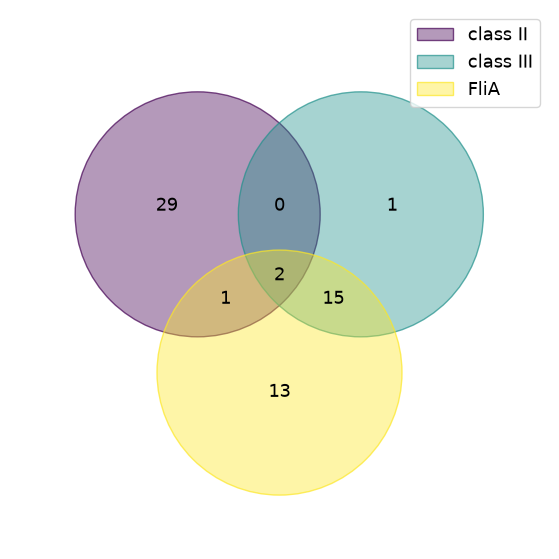


class II only (29):
['flgA', 'flgB', 'flgC', 'flgD', 'flgE', 'flgF', 'flgG', 'flgH', 'flgI', 'flgJ', 'flhA', 'flhB', 'flhE', 'fliA', 'fliE', 'fliF', 'fliG', 'fliH', 'fliI', 'fliJ', 'fliK', 'fliL', 'fliM', 'fliN', 'fliO', 'fliP', 'fliQ', 'fliR', 'fliY']

class III only (1):
['fliC']

FliA only (13):
['aer', 'b1923', 'flxA', 'modA', 'trg', 'tsr', 'uhpT', 'ves', 'ycgR', 'yhjH', 'yjcZ', 'yjdA', 'ynjH']

class II & class III only (0):
[]

class II & FliA only (1):
['fliZ']

class III & FliA only (15):
['cheA', 'cheB', 'cheR', 'cheW', 'cheY', 'cheZ', 'flgK', 'flgL', 'fliD', 'fliS', 'fliT', 'motA', 'motB', 'tap', 'tar']

class II & class III & FliA only (2):
['flgM', 'flgN']


In [22]:
plot_venn(
    class2,
    class3,
    FliA_genes,
    labels=["class II", "class III", "FliA"]
)

## correlation within class

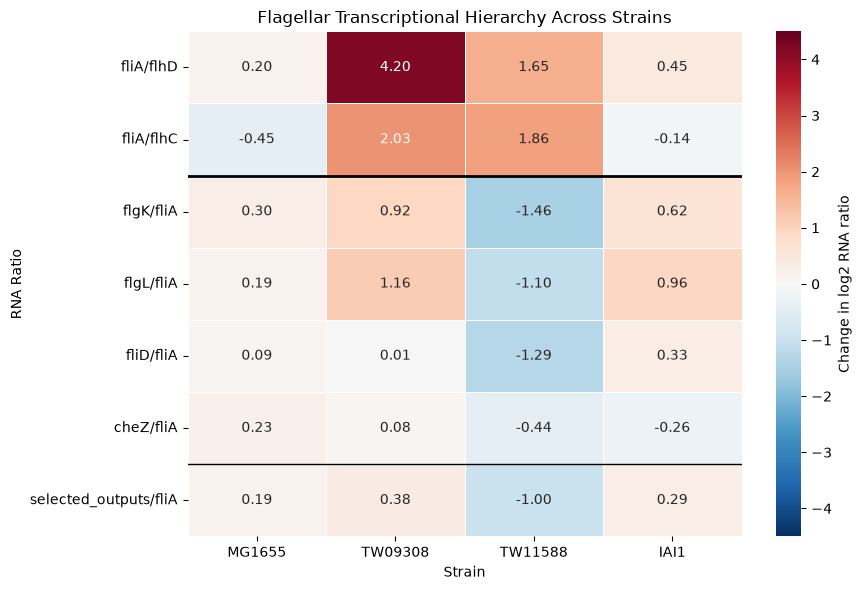

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("IBPGG/IBP project/results/RNA_ratio_changes.csv")

ratio_order = [
    "fliA/flhD",
    "fliA/flhC",
    "flgK/fliA",
    "flgL/fliA",
    "fliD/fliA",
    "cheZ/fliA",
    "selected_outputs/fliA"
]

strain_order = ["MG1655", "TW09308", "TW11588", "IAI1"]

heatmap_data = df.pivot(
    index="ratio",
    columns="strain",
    values="change_log2_ratio"
).reindex(index=ratio_order, columns=strain_order)

plt.figure(figsize=(9, 6))

ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-4.5,
    vmax=4.5,
    linewidths=0.5,
    cbar_kws={"label": "Change in log2 RNA ratio"}
)

ax.axhline(2, color="black", linewidth=2)
ax.axhline(6, color="black", linewidth=1)

plt.title("Flagellar Transcriptional Hierarchy Across Strains")
plt.xlabel("Strain")
plt.ylabel("RNA Ratio")

plt.tight_layout()
plt.show()

In [24]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

df = pd.read_csv(f"{RESULTS}/replicate_RNA_ratios.csv")

strains = ["MG1655", "TW09308", "TW11588", "IAI1"]
reference = "MG1655"

ratio_order = [
    "fliA/flhD",
    "fliA/flhC",
    "flgK/fliA",
    "flgL/fliA",
    "fliD/fliA",
    "cheZ/fliA",
    "selected_outputs/fliA"
]

results = []
changes = []

for ratio in ratio_order:
    sub = df[df["ratio"] == ratio].copy()
    sub["starvation"] = (sub["state"] == "starvation").astype(int)

    # Design matrix: strain + condition + interaction
    X = pd.DataFrame(index=sub.index)
    X["Intercept"] = 1.0
    X["starvation"] = sub["starvation"]

    for strain in strains[1:]:
        X[f"is_{strain}"] = (sub["strain"] == strain).astype(int)
        X[f"interaction_{strain}"] = (
            X[f"is_{strain}"] * sub["starvation"]
        )

    model = sm.OLS(
        sub["log2_raw_count_ratio"].astype(float),
        X.astype(float)
    ).fit(cov_type="HC3", use_t=True)

    # Starvation response in each strain
    def response_vector(strain):
        v = pd.Series(0.0, index=X.columns)
        v["starvation"] = 1.0

        if strain != reference:
            v[f"interaction_{strain}"] = 1.0

        return v.to_numpy()

    for strain in strains:
        contrast = model.t_test(response_vector(strain))

        changes.append({
            "ratio": ratio,
            "strain": strain,
            "change": float(np.asarray(contrast.effect).item())
        })

    # Only compare other strains against MG1655
    for strain in strains[1:]:

        contrast_vector = (
            response_vector(reference)
            - response_vector(strain)
        )

        test = model.t_test(contrast_vector)
        ci = test.conf_int()[0]

        results.append({
            "ratio": ratio,
            "comparison": f"MG1655 - {strain}",
            "difference": float(np.asarray(test.effect).item()),
            "ci_low": ci[0],
            "ci_high": ci[1],
            "pvalue": float(np.asarray(test.pvalue).item())
        })

stats_df = pd.DataFrame(results)

# FDR correction across 21 comparisons
stats_df["padj"] = multipletests(
    stats_df["pvalue"],
    method="fdr_bh"
)[1]

stats_df["significant"] = stats_df["padj"] < 0.05

change_df = pd.DataFrame(changes)

display(stats_df.sort_values("padj"))

,ratio,comparison,difference,ci_low,ci_high,pvalue,padj,significant
7,flgK/fliA,MG1655 - TW11588,1.767802,1.529198,2.006406,1.399619e-07,0.000003,True
10,flgL/fliA,MG1655 - TW11588,1.295950,0.793028,1.798872,3.449790e-04,0.003622,True
0,fliA/flhD,MG1655 - TW09308,-3.999311,-5.830691,-2.167932,1.006892e-03,0.007048,True
9,flgL/fliA,MG1655 - TW09308,-0.967650,-1.478606,-0.456694,2.389718e-03,0.012393,True
13,fliD/fliA,MG1655 - TW11588,1.376449,0.622734,2.130164,2.950750e-03,0.012393,True
4,fliA/flhC,MG1655 - TW11588,-2.306876,-3.653243,-0.960510,4.229320e-03,0.014803,True
19,selected_outputs/fliA,MG1655 - TW11588,1.192690,0.373177,2.012203,9.989787e-03,0.029969,True
6,flgK/fliA,MG1655 - TW09308,-0.616583,-1.174122,-0.059044,3.416335e-02,0.079714,False
3,fliA/flhC,MG1655 - TW09308,-2.477028,-4.676854,-0.277203,3.178600e-02,0.079714,False
1,fliA/flhD,MG1655 - TW11588,-1.452608,-2.991077,0.085860,6.111832e-02,0.128348,False


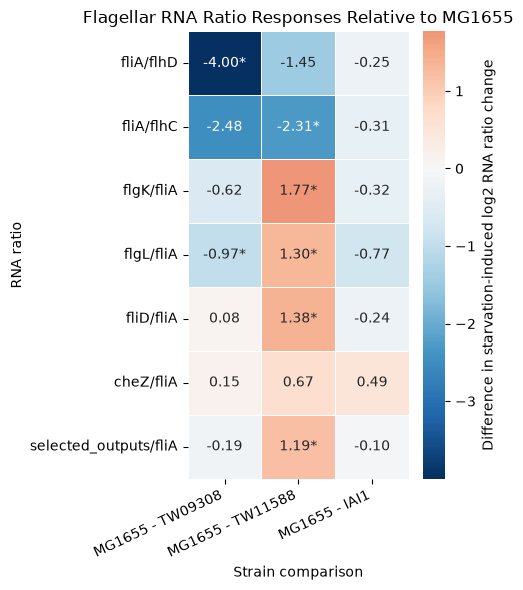

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

comparison_order = [
    "MG1655 - TW09308",
    "MG1655 - TW11588",
    "MG1655 - IAI1"
]

effect_matrix = stats_df.pivot(
    index="ratio",
    columns="comparison",
    values="difference"
).reindex(
    index=ratio_order,
    columns=comparison_order
)

q_matrix = stats_df.pivot(
    index="ratio",
    columns="comparison",
    values="padj"
).reindex_like(effect_matrix)

annotations = effect_matrix.copy().astype(str)

for row in effect_matrix.index:
    for col in effect_matrix.columns:
        value = effect_matrix.loc[row, col]
        q = q_matrix.loc[row, col]

        star = "*" if q < 0.05 else ""
        annotations.loc[row, col] = f"{value:.2f}{star}"

plt.figure(figsize=(5, 6))

sns.heatmap(
    effect_matrix,
    annot=annotations,
    fmt="",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Difference in starvation-induced log2 RNA ratio change"
    }
)

plt.title("Flagellar RNA Ratio Responses Relative to MG1655")
plt.xlabel("Strain comparison")
plt.ylabel("RNA ratio")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

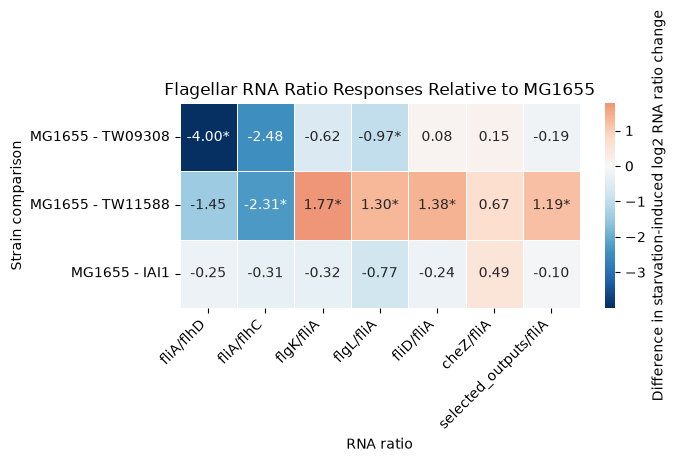

In [31]:
plt.figure(figsize=(7, 4))

sns.heatmap(
    effect_matrix.T,
    annot=annotations.T,
    fmt="",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Difference in starvation-induced log2 RNA ratio change"
    }
)

plt.title("Flagellar RNA Ratio Responses Relative to MG1655")
plt.xlabel("RNA ratio")
plt.ylabel("Strain comparison")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

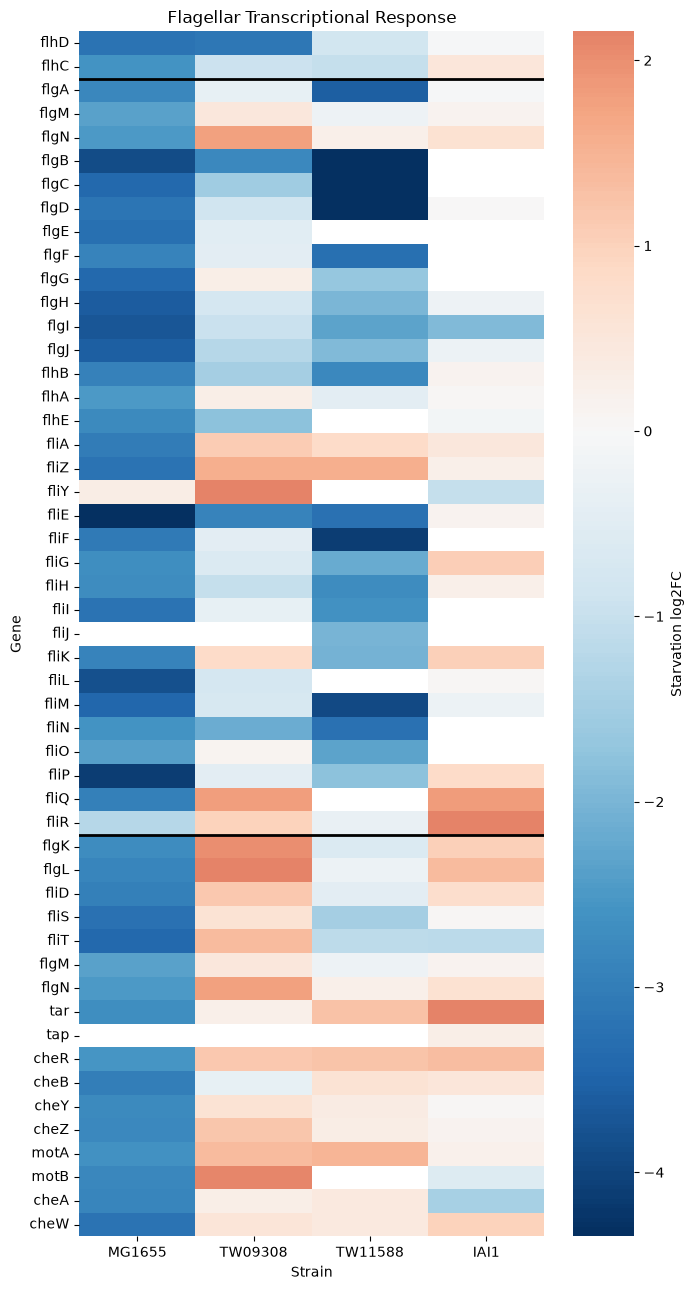

In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(r"IBPGG\IBP project\results")

strains = ["MG1655", "TW09308", "TW11588", "IAI1"]
relatives = strains[1:]

# Load DE results
de = {}

for strain in relatives:
    df = pd.read_csv(ROOT / f"DE_MG1655_{strain}.csv")

    # Exclude ambiguous gene names
    df = df.dropna(subset=["gene_name"])
    df = df.loc[~df["gene_name"].duplicated(keep=False)]

    de[strain] = df.set_index("gene_name")

# Combine log2FC
lfc = pd.concat(
    [de["TW09308"]["MG1655_log2FoldChange"].rename("MG1655")]
    + [
        de[s]["relative_log2FoldChange"].rename(s)
        for s in relatives
    ],
    axis=1
)

# Regulatory classes
gene_classes = {
    "Class I": class1,
    "Class II": class2,
    "Class III": class3
}

class_map = {
    gene: cls
    for cls, genes in gene_classes.items()
    for gene in genes
}

gene_order = [
    gene
    for genes in gene_classes.values()
    for gene in dict.fromkeys(genes)
    if gene in lfc.index
]

heatmap_data = lfc.reindex(gene_order)[strains]

fig, ax = plt.subplots(figsize=(7, 13))

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    robust=True,
    cbar_kws={"label": "Starvation log2FC"},
    ax=ax
)

# Separate regulatory classes
boundary = 0
for cls, genes in list(gene_classes.items())[:-1]:
    boundary += sum(g in heatmap_data.index for g in dict.fromkeys(genes))
    ax.axhline(boundary, color="black", linewidth=2)

ax.set_title("Flagellar Transcriptional Response")
ax.set_xlabel("Strain")
ax.set_ylabel("Gene")

plt.tight_layout()
plt.show()

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read data
counts = pd.read_csv("GSE77325_raw_count.txt", sep="\t", index_col=0)

de = {
    "TW09308": pd.read_csv(f"{RESULTS}\\DE_MG1655_TW09308.csv"),
    "TW11588": pd.read_csv(f"{RESULTS}\\DE_MG1655_TW11588.csv"),
    "IAI1": pd.read_csv(f"{RESULTS}\\DE_MG1655_IAI1.csv")
}

# Define regulatory classes
gene_classes = {
    "Class I": "flhD flhC".split(),
    "Class II": (
        "flgA flgM flgN flgB flgC flgD flgE flgF flgG flgH flgI flgJ "
        "flhB flhA flhE fliA fliZ fliY fliE fliF fliG fliH fliI fliJ "
        "fliK fliL fliM fliN fliO fliP fliQ fliR"
    ).split(),
    "Class III": (
        "flgK flgL fliD fliS fliT fliC tar tap cheR cheB cheY cheZ "
        "motA motB cheA cheW"
    ).split()
}

# Shared genes tested in all three comparisons
common = set.intersection(
    *(set(d["gene_name"].dropna()) for d in de.values())
)

# gene_name -> pan_gene
mapping = pd.concat(
    [d[["gene_name", "pan_gene"]] for d in de.values()]
).dropna().drop_duplicates()

# Remove ambiguous mappings
unambiguous = (
    mapping.groupby("gene_name")["pan_gene"].nunique()
)
mapping = mapping[
    mapping["gene_name"].isin(unambiguous[unambiguous == 1].index)
]

name_to_pan = (
    mapping.drop_duplicates("gene_name")
    .set_index("gene_name")["pan_gene"]
)

def compute_coordination(gene_names, strain, condition_only=False):
    samples = [
        col for col in counts.columns
        if col.startswith(strain)
        and (
            not condition_only
            or "CC" in col
            or "_starv_" in col
        )
    ]

    genes = [
        g for g in dict.fromkeys(gene_names)
        if g in common
        and g in name_to_pan.index
        and name_to_pan[g] in counts.index
    ]

    pan_ids = name_to_pan.loc[genes].tolist()
    expression = counts.loc[pan_ids, samples].copy()
    expression.index = genes

    # log2 CPM normalization
    library_sizes = counts[samples].sum(axis=0)
    expression = np.log2(
        expression.div(library_sizes, axis=1) * 1e6 + 1
    )

    # Remove genes with no variation
    expression = expression.loc[expression.var(axis=1) > 0]

    corr = expression.T.corr(method="pearson")

    values = corr.to_numpy()[
        np.triu_indices(len(corr), k=1)
    ]
    values = values[np.isfinite(values)]

    return {
        "coordination": values.mean() if len(values) else np.nan,
        "n_genes": expression.shape[0],
        "n_pairs": len(values)
    }


strains = ["MG1655", "TW09308", "TW11588", "IAI1"]

results = []

for strain in strains:
    for cls, genes in gene_classes.items():
        result = compute_coordination(genes, strain)

        results.append({
            "Strain": strain,
            "Class": cls,
            **result
        })

coord_df = pd.DataFrame(results)

coord_matrix = coord_df.pivot(
    index="Strain",
    columns="Class",
    values="coordination"
).reindex(
    index=strains,
    columns=["Class I", "Class II", "Class III"]
)

display(coord_matrix)

Class,Class I,Class II,Class III
Strain,,,
MG1655,0.998175,0.977623,0.992387
TW09308,0.878109,0.233474,0.214299
TW11588,0.953098,0.602692,0.646839
IAI1,0.874295,0.385715,0.287984


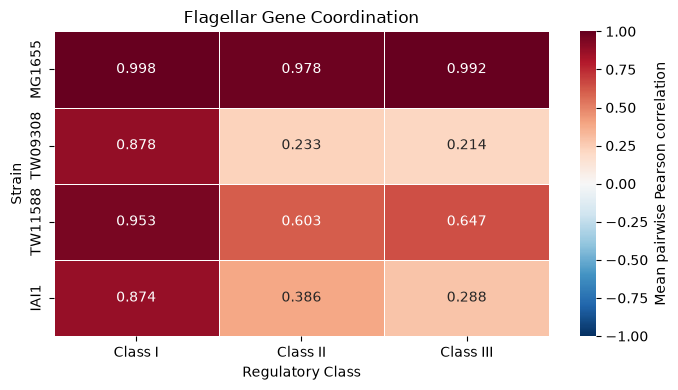

In [28]:
plt.figure(figsize=(7, 4))

sns.heatmap(
    coord_matrix,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Mean pairwise Pearson correlation"}
)

plt.title("Flagellar Gene Coordination")
plt.xlabel("Regulatory Class")
plt.ylabel("Strain")

plt.tight_layout()
plt.show()

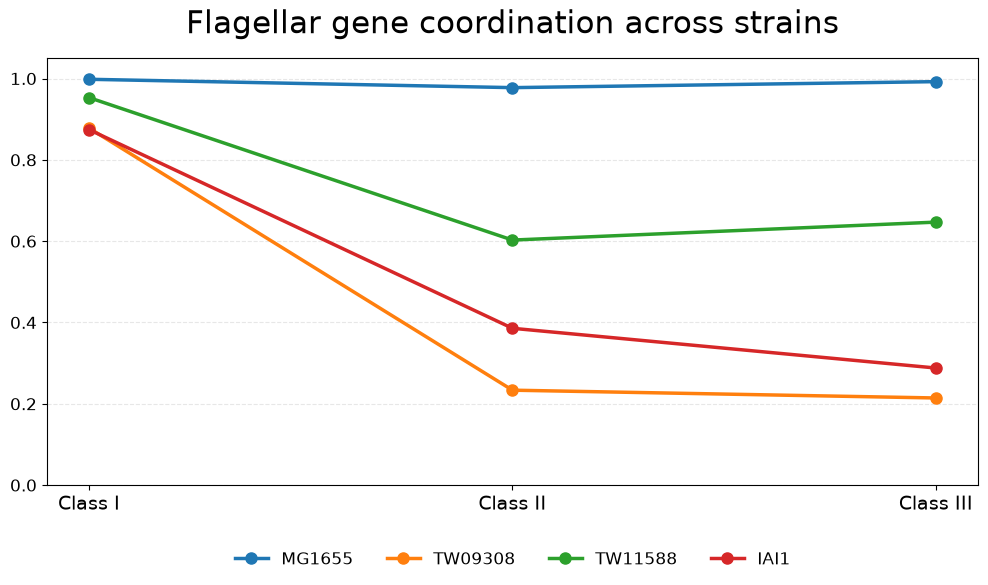

In [29]:
x = range(len(coord_matrix.columns))

plt.figure(figsize=(10, 6))

for strain in coord_matrix.index:
    plt.plot(
        x,
        coord_matrix.loc[strain],
        marker="o",
        linewidth=2.5,
        markersize=8,
        label=strain
    )

plt.xticks(x, coord_matrix.columns, fontsize=14)
plt.yticks(fontsize=12)
plt.ylim(0, 1.05)

plt.title("Flagellar gene coordination across strains", fontsize=22, pad=18)

plt.ylabel("")
plt.xlabel("")

plt.grid(True, axis="y", linestyle="--", alpha=0.3)

plt.legend(
    title="",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()